# Archive-wide analysis: cross-production keyness

The vocabulary of each production compared against all other productions of the archive (keyness).

In [1]:
import re
from collections import Counter
from pathlib import Path

import spacy
import contractions
import pandas as pd
import numpy as np
from tqdm import tqdm
from nltk.corpus import stopwords
from sklearn.feature_extraction.text import CountVectorizer
from plotnine import *

In [2]:
MIN_ANNOTATIONS = 100     # minimum text annotations per piece

# 'g2' or 'log_ratio' (effect size among the significant words, brings up rarer vocabulary)
RANK_BY = 'g2'

LANG = 'en'   # 'de' or 'en', switches the figure labels

def L(de, en):
    return de if LANG == 'de' else en

PASTEL_CYCLE = ['#cd867e', '#7ec5cd', '#7ecd86', '#867ecd', '#c5cd7e', '#cd7ec5']
BAR_GREY     = '#6b6b6b'
theme_set(theme_minimal() + theme(plot_title=element_text(size=12),
                                  plot_subtitle=element_text(size=9),
                                  legend_title=element_blank()))

pieces_df = pd.read_csv('pm1-tfc-2016-pieces.csv')
events_df = pd.read_csv('pm1-tfc-2016-events.csv')

events_df['happened_at'] = pd.to_datetime(events_df['happened_at'], errors='coerce')
piece_map = pieces_df.set_index('id')['title'].to_dict()

# text annotations only, otherwise pieces with mostly videos would count (e.g. Decreation: 107 videos, 1 annotation)
annotation_events = events_df[~events_df['event_type'].isin(['video', 'note'])]
piece_counts = annotation_events['piece_id'].value_counts()
included_pieces = sorted(piece_counts[piece_counts >= MIN_ANNOTATIONS].index.tolist())

print(f'Pieces with >= {MIN_ANNOTATIONS} text annotations: {len(included_pieces)}')
for pid in included_pieces:
    if pid in piece_map:
        print(f'  {int(pid)}: {piece_map[pid]} ({int(piece_counts[pid])} annotations)')

n_text = len(annotation_events)
n_included = int(annotation_events['piece_id'].isin(included_pieces).sum())
print(f'\nText annotations in the export (all pieces, without video entries and notes): {n_text}')
print(f'Productions with >= {MIN_ANNOTATIONS} text annotations: {len(included_pieces)}, together {n_included} text annotations')

Pieces with >= 100 text annotations: 12
  17: Yes We Can't (942 annotations)
  42: I Don't Believe in Outer Space (693 annotations)
  43: Angolo Scuro (110 annotations)
  44: Nowhere and Everywhere at the Same Time (125 annotations)
  45: The Returns (196 annotations)
  52: Theatrical Arsenal 2* (812 annotations)
  104: Whole in the Head (715 annotations)
  108: Sider (900 annotations)
  109: STELLENTSTELLEN (563 annotations)
  110: Now This When Not That (517 annotations)
  115: Study 1 (110 annotations)
  117: Hellerau (699 annotations)

Text annotations in the export (all pieces, without video entries and notes): 6516
Productions with >= 100 text annotations: 12, together 6382 text annotations


## Preprocessing and name filtering

Same pipeline as in the per-piece notebooks. The name list has to cover the whole archive here. Automatic filtering via named entity recognition did not work: spaCy's PERSON tagger flags content words like *hamlet*, *map* or *tuna*, and also reference names (*woolf*, *shakespeare*) that are exactly the vocabulary this analysis should surface. So the list is curated by hand from the NER candidates.


In [3]:
nlp = spacy.load('en_core_web_sm')
nlp.max_length = 5_000_000

filename_pattern = re.compile(r'^(\d{6,}|\d{4}-\d{2}-\d{2}).*\.\w{2,4}$', re.IGNORECASE)

def combine_annotation_text(row):
    title = str(row['title']) if pd.notna(row['title']) else ''
    description = str(row['description']) if pd.notna(row['description']) else ''
    if filename_pattern.match(title.strip()):
        title = ''
    if title and not title.endswith('.'):
        title += '.'
    return f'{title} {description}'.strip()

def clean_text(text):
    if pd.isna(text) or not text:
        return ''
    text = contractions.fix(text)
    text = re.sub(r'[\n\r\*]+', ' ', text)
    text = re.sub(r'__+', ' ', text)
    text = re.sub(r'\b\d+\b', '', text)
    text = re.sub(r'(?<=\w)-(?=\w)', ' ', text)
    text = re.sub(r'<br\s*/?>', ' ', text, flags=re.IGNORECASE)
    text = re.sub(r'<[^>]+>', ' ', text)
    text = re.sub(r'[<>]', ' ', text)
    text = re.sub(r'\s{2,}', ' ', text).strip()
    return text

def spacy_lemmatize_batch(texts):
    return [' '.join(tok.lemma_.lower() for tok in doc
                     if tok.is_alpha and not tok.is_stop and len(tok.lemma_) >= 2)
            for doc in nlp.pipe(texts, batch_size=100)]

# Manual performer list
manual_names = [
    'amancio', 'ander', 'bill', 'billy', 'brigel', 'cy', 'cyril', 'dana', 'dave',
    'david', 'esth', 'esther', 'fab', 'fabrice', 'feya', 'freya', 'jasu', 'john',
    'jon', 'jone', 'jones', 'josh', 'kati', 'katy', 'katya', 'liz', 'manci',
    'mancie', 'monica', 'nic', 'nicole', 'pari', 'riley', 'rob', 'roberta',
    'simon', 'steven', 'stevens', 'tanja', 'til', 'tilman', 'ya', 'yas', 'yasu', 'yoko',
]
# Curated additions from an NER candidate review (clearly company members/crew)
ner_added_names = [
    'chris', 'kern', 'morrow', 'inma', 'natasha', 'katja', 'fran', 'frances',
    'amanci', 'danny', 'ildiko', 'ioannis', 'tillman', 'donya', 'moni', 'ester',
    'alessio', 'alva',
]
confirmed_names = sorted(set(manual_names) | set(ner_added_names))
stop_en = set(stopwords.words('english'))
custom_stopwords = list(stop_en.union(confirmed_names))
print(f'Performer/crew names in stoplist: {len(confirmed_names)}; total stopwords: {len(custom_stopwords)}')

Performer/crew names in stoplist: 63; total stopwords: 261


In [4]:
piece_word_freqs = {}
piece_total_words = {}
piece_docs = {}      # lemmatised text per annotation, for the bootstrap
piece_authors = {}   # annotator per annotation, for the annotator check

for piece_id in tqdm(included_pieces, desc='Processing pieces'):
    group = annotation_events[annotation_events['piece_id'] == piece_id].copy()
    # drop entries that are only a file name
    is_filename_title = group['title'].apply(
        lambda t: bool(filename_pattern.match(str(t))) if pd.notna(t) else False)
    is_filename_desc = group['description'].apply(
        lambda d: bool(filename_pattern.match(str(d))) if pd.notna(d) else False)
    group = group[~(is_filename_title & (group['description'].isna() | is_filename_desc))].copy()
    group['text'] = group.apply(combine_annotation_text, axis=1)
    group['clean'] = group['text'].apply(clean_text)
    group = group[group['clean'].str.len() > 0]
    lem_texts = spacy_lemmatize_batch(group['clean'].tolist())
    vectorizer = CountVectorizer(stop_words=custom_stopwords)
    X = vectorizer.fit_transform(lem_texts)
    words = vectorizer.get_feature_names_out()
    counts = X.sum(axis=0).A1
    piece_word_freqs[piece_id] = Counter(dict(zip(words, counts)))
    piece_total_words[piece_id] = int(counts.sum())
    piece_docs[piece_id] = lem_texts
    piece_authors[piece_id] = (group['created_by'].str.extract(r'^([A-Za-z]+)')[0].str.capitalize()
                               .fillna('(no author)').tolist())

print('\nAnnotations and tokens per piece (after cleaning):')
for pid in included_pieces:
    print(f'  {piece_map.get(pid, pid)}: {len(piece_docs[pid])} annotations, {piece_total_words[pid]} tokens')
print(f'Total: {sum(len(d) for d in piece_docs.values())} annotations in {len(included_pieces)} productions')

Processing pieces:   0%|          | 0/12 [00:00<?, ?it/s]

Processing pieces:   8%|▊         | 1/12 [00:04<00:44,  4.02s/it]

Processing pieces:  17%|█▋        | 2/12 [00:09<00:48,  4.89s/it]

Processing pieces:  25%|██▌       | 3/12 [00:10<00:27,  3.08s/it]

Processing pieces:  33%|███▎      | 4/12 [00:12<00:20,  2.62s/it]

...

Processing pieces:  83%|████████▎ | 10/12 [00:33<00:05,  2.98s/it]

Processing pieces:  92%|█████████▏| 11/12 [00:33<00:02,  2.12s/it]

Processing pieces: 100%|██████████| 12/12 [00:36<00:00,  2.30s/it]

Processing pieces: 100%|██████████| 12/12 [00:36<00:00,  3.06s/it]


Annotations and tokens per piece (after cleaning):
  Yes We Can't: 942 annotations, 9633 tokens
  I Don't Believe in Outer Space: 693 annotations, 13325 tokens
  Angolo Scuro: 110 annotations, 2622 tokens
  Nowhere and Everywhere at the Same Time: 123 annotations, 4644 tokens
  The Returns: 190 annotations, 3616 tokens
  Theatrical Arsenal 2*: 795 annotations, 17238 tokens
  Whole in the Head: 708 annotations, 10232 tokens
  Sider: 897 annotations, 11458 tokens
  STELLENTSTELLEN: 556 annotations, 3794 tokens
  Now This When Not That: 464 annotations, 4101 tokens
  Study 1: 98 annotations, 362 tokens
  Hellerau: 698 annotations, 6417 tokens
Total: 6274 annotations in 12 productions


## Cross-piece keyness

For every word in every production, G² (Dunning) against the rest of the archive, minimum frequency 3; positive G² means overrepresented in that production, G² ≥ 10.83 corresponds to p < 0.001. Log Ratio is computed as an effect size. Same measures as for the keyness against the Brown corpus in the per-production notebooks. `RANK_BY` switches the ranking.

In [5]:
# Dunning's G2: positive = overrepresented in the target piece
def compute_g2(O1, O2, N1, N2):
    def safe_log(x): return np.log(x) if x > 0 else 0.0
    N = N1 + N2
    p  = (O1 + O2) / N if N > 0 else 0.0
    p1 = O1 / N1 if N1 > 0 else 0.0
    p2 = O2 / N2 if N2 > 0 else 0.0
    L_null = (O1 * safe_log(p)  + (N1 - O1) * safe_log(1 - p) +
              O2 * safe_log(p)  + (N2 - O2) * safe_log(1 - p))
    L_alt  = (O1 * safe_log(p1) + (N1 - O1) * safe_log(1 - p1) +
              O2 * safe_log(p2) + (N2 - O2) * safe_log(1 - p2))
    g2 = 2 * (L_alt - L_null)
    return g2 if p1 >= p2 else -g2

def log_ratio(O1, O2, N1, N2):
    return float(np.log2(((O1 if O1 > 0 else 0.5) / N1) /
                         ((O2 if O2 > 0 else 0.5) / N2)))

MIN_FREQ_KEYNESS = 3
G2_CRIT = 10.83     # p < 0.001, df = 1

total_freq = Counter()
for freq in piece_word_freqs.values():
    total_freq.update(freq)
total_N = sum(piece_total_words.values())

rows = []
for piece_id in included_pieces:
    N1 = piece_total_words[piece_id]
    N2 = total_N - N1
    for word, O1 in piece_word_freqs[piece_id].items():
        if O1 < MIN_FREQ_KEYNESS:
            continue
        O2 = total_freq[word] - O1
        rows.append({
            'piece_id': piece_id,
            'piece': piece_map.get(piece_id, str(int(piece_id))),
            'word': word, 'O1': int(O1),
            'g2': compute_g2(O1, O2, N1, N2),
            'log_ratio': log_ratio(O1, O2, N1, N2),
        })

keyness_df = pd.DataFrame(rows)

keyness_df['O2'] = [int(total_freq[w] - o1) for w, o1 in zip(keyness_df['word'], keyness_df['O1'])]
print(f'Keyness entries (freq >= {MIN_FREQ_KEYNESS}): {len(keyness_df)}')
keyness_df[keyness_df['g2'] > 0].sort_values('g2', ascending=False).head(10)

Keyness entries (freq >= 3): 6164


,piece_id,piece,word,O1,g2,log_ratio,O2
4226,108.0,Sider,board,484,1723.274021,6.400276,38
4553,108.0,Sider,map,220,801.191414,6.810260,13
4122,104.0,Whole in the Head,tuna,191,704.462290,6.323203,18
151,17.0,Yes We Can't,duet,323,525.552970,2.683934,406
2189,45.0,The Returns,art,93,484.383275,6.614658,22
5465,110.0,Now This When Not That,pom,72,441.815505,11.514904,0
4449,108.0,Sider,hamlet,106,431.700073,10.457261,0
2976,52.0,Theatrical Arsenal 2*,light,234,349.409435,2.907641,127
84,17.0,Yes We Can't,clap,85,343.942147,7.423271,4
86,17.0,Yes We Can't,clapping,81,332.754460,7.768767,3


### Compact overview

One row per production, the five most distinctive words with their G² value. The shading encodes keyness relative to the strongest word of the same production, since absolute G² values are not comparable between corpora of different sizes.

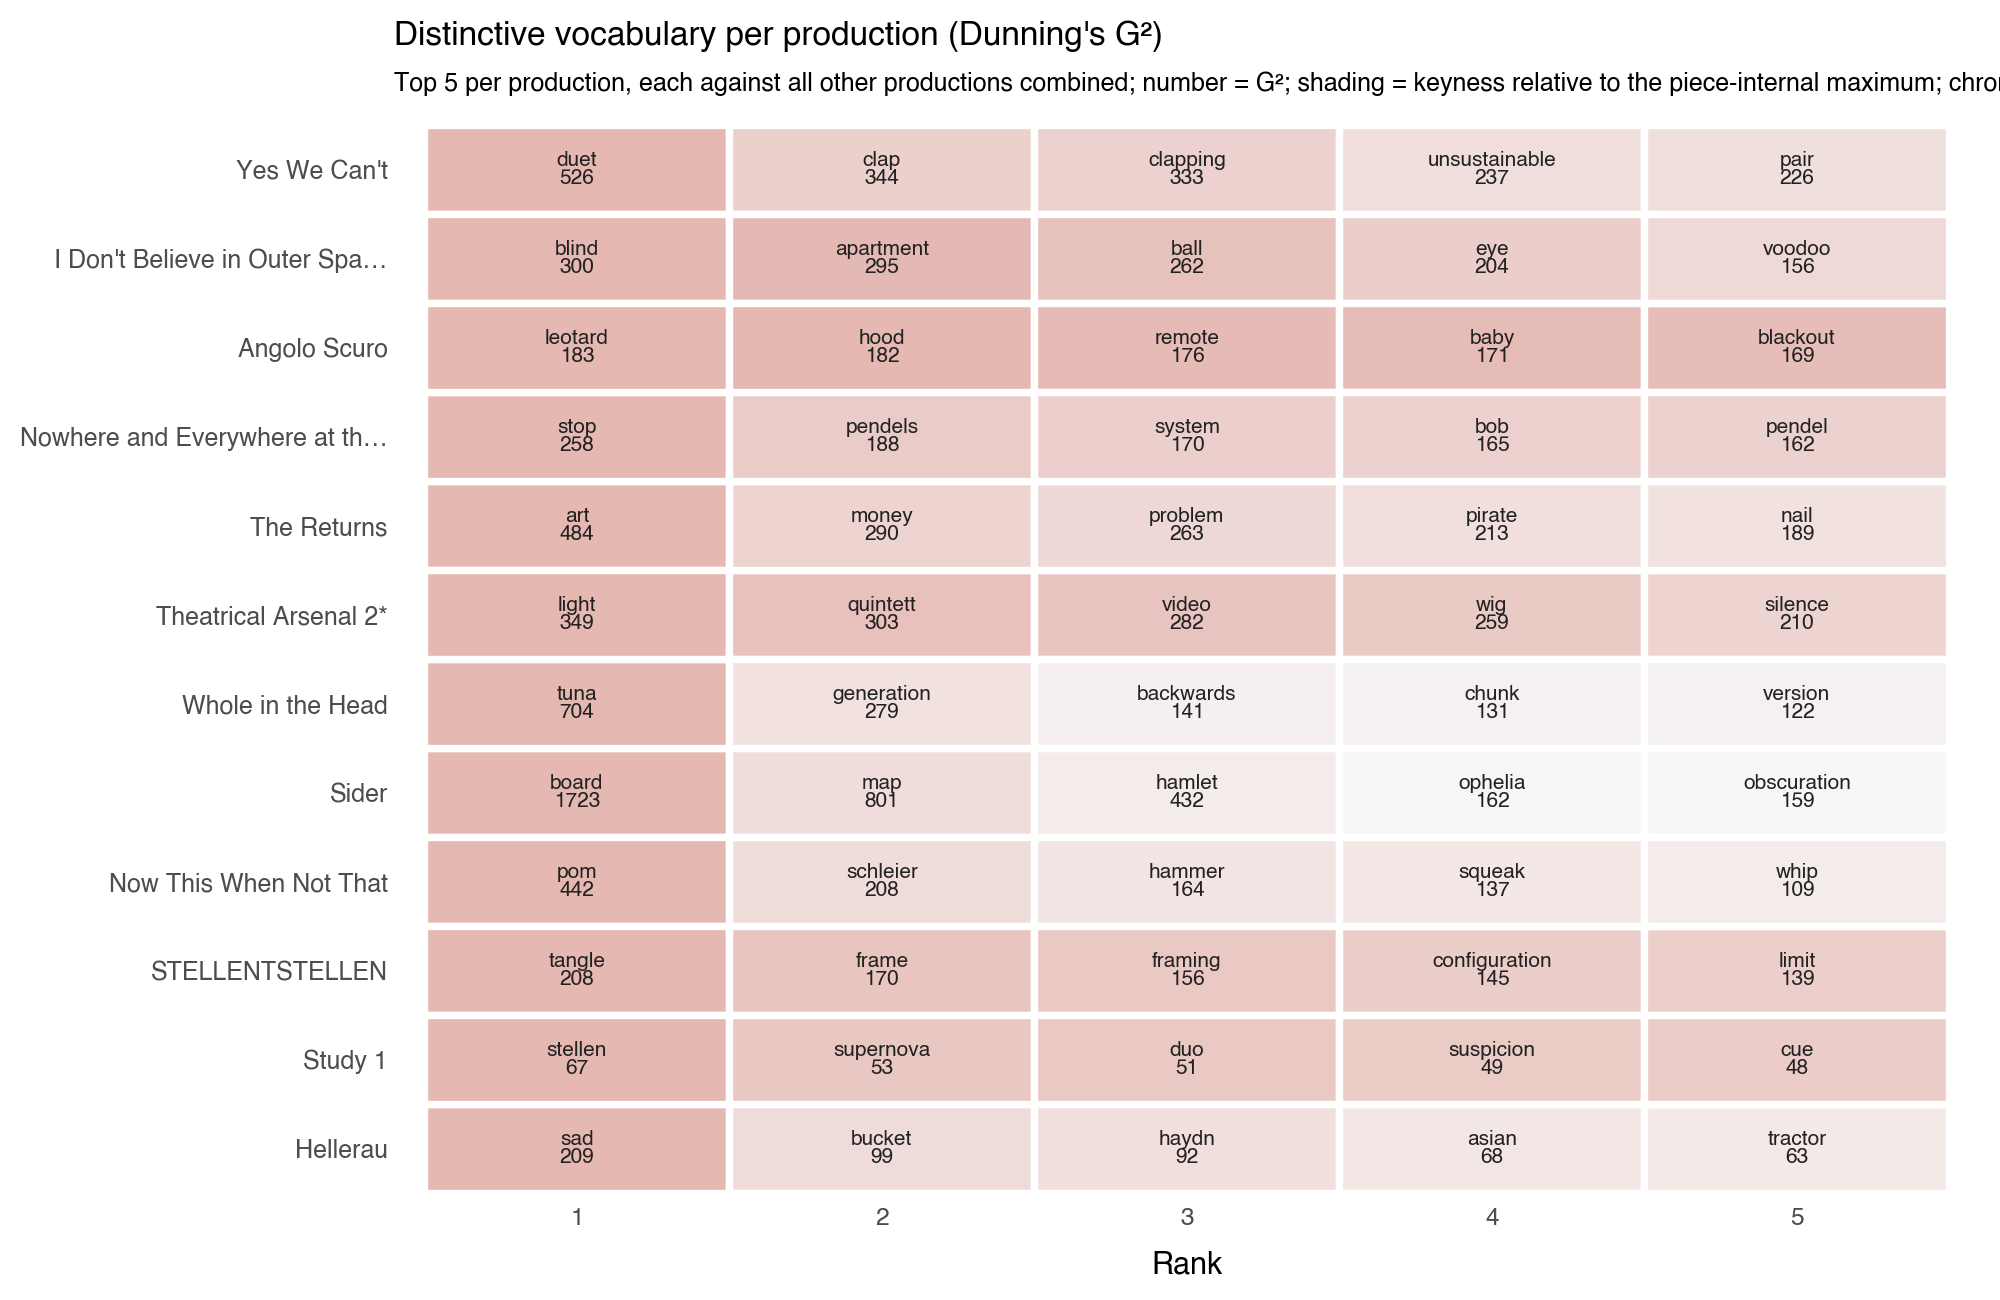

In [6]:
TOP_COMPACT = 5

def shorten(title, max_len=28):
    return title[:max_len] + '…' if len(title) > max_len else title

# Ranking by G² or, with RANK_BY='log_ratio', by effect size among the significant words only.
if RANK_BY == 'log_ratio':
    base = keyness_df[keyness_df['g2'] >= G2_CRIT].copy()
else:
    base = keyness_df[keyness_df['g2'] > 0].copy()

comp = (base.sort_values(RANK_BY, ascending=False)
        .groupby('piece_id').head(TOP_COMPACT).copy())
comp['rank'] = comp.groupby('piece_id')[RANK_BY].rank(ascending=False, method='first').astype(int)
comp['rel'] = comp.groupby('piece_id')[RANK_BY].transform(lambda s: s / s.max())
comp['label'] = comp['word'] + '\n' + comp[RANK_BY].map(lambda v: f'{v:.0f}' if RANK_BY == 'g2' else f'{v:.1f}')

# Chronological order (first annotation date), earliest production on top
first_dates = (annotation_events[annotation_events['piece_id'].isin(included_pieces)]
               .groupby('piece_id')['happened_at'].min().sort_values())
order_titles = [shorten(piece_map.get(pid, str(int(pid)))) for pid in first_dates.index]
comp['piece_short'] = comp['piece_id'].map(lambda p: shorten(piece_map.get(p, str(int(p)))))
comp['piece_short'] = pd.Categorical(comp['piece_short'], categories=order_titles[::-1], ordered=True)

p_compact = (
    ggplot(comp, aes(x='factor(rank)', y='piece_short'))
    + geom_tile(aes(fill='rel'), color='white', size=1.5)
    + geom_text(aes(label='label'), size=7.5, color='#222222', lineheight=0.9)
    + scale_fill_gradient(low='#f7f7f7', high='#e5b8b2')
    + labs(title=L('Distinktives Vokabular je Produktion (Dunnings G²)',
                   "Distinctive vocabulary per production (Dunning's G²)"),
           subtitle=L('Top 5 je Produktion, jeweils gegen alle übrigen Produktionen; Zahl = G²; '
                      'Färbung = Keyness relativ zum stückinternen Maximum; chronologisch sortiert',
                      'Top 5 per production, each against all other productions combined; number = G²; '
                      'shading = keyness relative to the piece-internal maximum; chronological order'),
           x=L('Rang', 'Rank'), y='')
    + theme(figure_size=(10, 6.5),
            panel_grid=element_blank(),
            axis_ticks=element_blank(),
            axis_text_y=element_text(size=9),
            legend_position='none')
)
p_compact

### Scores and stability

The corpora are small. To check how much the top five depend on the sample: bootstrap over the annotations of each production (200 resamples, rest of the archive fixed); `top5_share` is the share of resamples in which a word is among the top five again.

In [7]:
def g2_vec(O1, O2, N1, N2):
    # vectorised compute_g2
    O1 = np.asarray(O1, dtype=float); O2 = np.asarray(O2, dtype=float)
    N = N1 + N2
    p, p1, p2 = (O1 + O2) / N, O1 / N1, O2 / N2
    def xlogy(x, y):
        with np.errstate(divide='ignore', invalid='ignore'):
            return np.where(x > 0, x * np.log(np.where(y > 0, y, 1.0)), 0.0)
    L_null = xlogy(O1, p) + xlogy(N1 - O1, 1 - p) + xlogy(O2, p) + xlogy(N2 - O2, 1 - p)
    L_alt  = xlogy(O1, p1) + xlogy(N1 - O1, 1 - p1) + xlogy(O2, p2) + xlogy(N2 - O2, 1 - p2)
    g2 = 2 * (L_alt - L_null)
    return np.where(p1 >= p2, g2, -g2)

def lr_vec(O1, O2, N1, N2):
    O1 = np.where(np.asarray(O1) > 0, O1, 0.5); O2 = np.where(np.asarray(O2) > 0, O2, 0.5)
    return np.log2((O1 / N1) / (O2 / N2))

B_BOOT = 200
rng = np.random.default_rng(42)
stab_rows = []
for piece_id in included_pieces:
    vec = CountVectorizer(stop_words=custom_stopwords)
    Xp = vec.fit_transform(piece_docs[piece_id])
    vocab_p = vec.get_feature_names_out()
    rest = np.array([total_freq[w] - piece_word_freqs[piece_id][w] for w in vocab_p])
    N2 = total_N - piece_total_words[piece_id]
    top_words = comp[comp['piece_id'] == piece_id].sort_values('rank')['word'].tolist()
    hits = Counter()
    for _ in range(B_BOOT):
        rows_b = rng.integers(0, Xp.shape[0], Xp.shape[0])
        cnt = np.asarray(Xp[rows_b].sum(axis=0)).ravel()
        N1 = cnt.sum()
        g2 = g2_vec(cnt, rest, N1, N2)
        if RANK_BY == 'log_ratio':
            score = np.where((cnt >= MIN_FREQ_KEYNESS) & (g2 >= G2_CRIT), lr_vec(cnt, rest, N1, N2), -np.inf)
        else:
            score = np.where((cnt >= MIN_FREQ_KEYNESS) & (g2 > 0), g2, -np.inf)
        top_b = set(vocab_p[np.argsort(-score)[:TOP_COMPACT]])
        hits.update(w for w in top_words if w in top_b)
    for w in top_words:
        r = keyness_df[(keyness_df['piece_id'] == piece_id) & (keyness_df['word'] == w)].iloc[0]
        stab_rows.append({'piece': piece_map.get(piece_id, str(int(piece_id))), 'word': w,
                          'O1': int(r['O1']), 'O2': int(r['O2']), 'g2': round(r['g2'], 1),
                          'log_ratio': round(r['log_ratio'], 2), 'top5_share': hits[w] / B_BOOT})
stability_df = pd.DataFrame(stab_rows)
print(stability_df.to_string(index=False))
print(f"\nMedian top-5 stability over all productions: {stability_df['top5_share'].median():.2f}")

                                  piece          word  O1  O2     g2  log_ratio  top5_share
                           Yes We Can't          duet 323 406  525.6       2.68       1.000
                           Yes We Can't          clap  85   4  343.9       7.42       1.000
                           Yes We Can't      clapping  81   3  332.8       7.77       0.995
                           Yes We Can't unsustainable  59   3  237.3       7.31       0.615
                           Yes We Can't          pair  76  26  226.0       4.56       0.520
         I Don't Believe in Outer Space         blind  95   9  299.7       5.88       0.965
         I Don't Believe in Outer Space     apartment  85   3  295.1       7.30       1.000
         I Don't Believe in Outer Space          ball 119  49  261.9       3.76       0.970
         I Don't Believe in Outer Space           eye 134 111  204.3       2.75       0.895
         I Don't Believe in Outer Space        voodoo  51   6  155.7       5.56 

### Annotators

Differences in vocabulary can also be differences in who wrote the notes. Below: the share of the main annotator per production (initials; part of the export has no author), and as a check the keyness within the main annotator's annotations only (productions with at least 100 of them).

In [8]:
# initials as in pm1_archive_analytics
all_names = (pd.read_csv('pm1-tfc-2016-events.csv', usecols=['created_by'])['created_by']
             .str.lower().str.extract(r'^([a-z]+)')[0].str.capitalize())
initials, used = {}, set()
for name in all_names.value_counts().index:
    label, k = name[0] + '.', 2
    while label in used:
        label, k = name[:k] + '.', k + 1
    used.add(label)
    initials[name] = label

MAIN = pd.Series([a for pid in included_pieces for a in piece_authors[pid] if a != '(no author)']).value_counts().idxmax()
print(f'Main annotator: {initials[MAIN]}\n')

author_rows = []
for pid in included_pieces:
    vc = pd.Series(piece_authors[pid]).value_counts()
    known = vc.drop('(no author)', errors='ignore')
    author_rows.append({'piece': piece_map.get(pid, str(int(pid))), 'annotations': int(vc.sum()),
                        'no_author': round(vc.get('(no author)', 0) / vc.sum(), 2),
                        'top_annotator': initials[known.index[0]] if len(known) else '-',
                        'main_share': round(vc.get(MAIN, 0) / vc.sum(), 2),
                        'main_share_of_known': round(known.get(MAIN, 0) / known.sum(), 2) if len(known) else float('nan')})
authors_df = pd.DataFrame(author_rows)
print(authors_df.to_string(index=False))

# keyness within the main annotator's annotations only
main_freqs, main_tokens = {}, {}
for pid in included_pieces:
    docs = [d for d, a in zip(piece_docs[pid], piece_authors[pid]) if a == MAIN]
    if len(docs) >= 100:
        vec = CountVectorizer(stop_words=custom_stopwords)
        Xm = vec.fit_transform(docs)
        main_freqs[pid] = Counter(dict(zip(vec.get_feature_names_out(), Xm.sum(axis=0).A1)))
        main_tokens[pid] = int(Xm.sum())
main_total = Counter()
for f in main_freqs.values():
    main_total.update(f)
main_N = sum(main_tokens.values())

check_rows = []
for pid, freq in main_freqs.items():
    words_m = [w for w, o in freq.items() if o >= MIN_FREQ_KEYNESS]
    o1 = np.array([freq[w] for w in words_m]); o2 = np.array([main_total[w] - freq[w] for w in words_m])
    g2 = g2_vec(o1, o2, main_tokens[pid], main_N - main_tokens[pid])
    top_main = [words_m[i] for i in np.argsort(-g2)[:TOP_COMPACT] if g2[i] > 0]
    top_full = comp[comp['piece_id'] == pid].sort_values('rank')['word'].tolist()
    check_rows.append({'piece': piece_map.get(pid, str(int(pid))), 'top5_all_annotators': ', '.join(top_full),
                       'top5_main_annotator_only': ', '.join(top_main), 'shared': len(set(top_full) & set(top_main))})
check_df = pd.DataFrame(check_rows)
print('\n' + check_df.to_string(index=False))

Main annotator: F.

                                  piece  annotations  no_author top_annotator  main_share  main_share_of_known
                           Yes We Can't          942       0.36            F.        0.29                 0.45
         I Don't Believe in Outer Space          693       0.38            F.        0.51                 0.83
                           Angolo Scuro          110       0.04            F.        0.92                 0.95
Nowhere and Everywhere at the Same Time          123       0.28            F.        0.72                 1.00
                            The Returns          190       0.41            F.        0.54                 0.91
                  Theatrical Arsenal 2*          795       0.34            F.        0.31                 0.47
                      Whole in the Head          708       0.46            F.        0.46                 0.85
                                  Sider          897       0.43            F.        0.43   

### Facet view

Top 10 words per production, more useful on screen than in print.


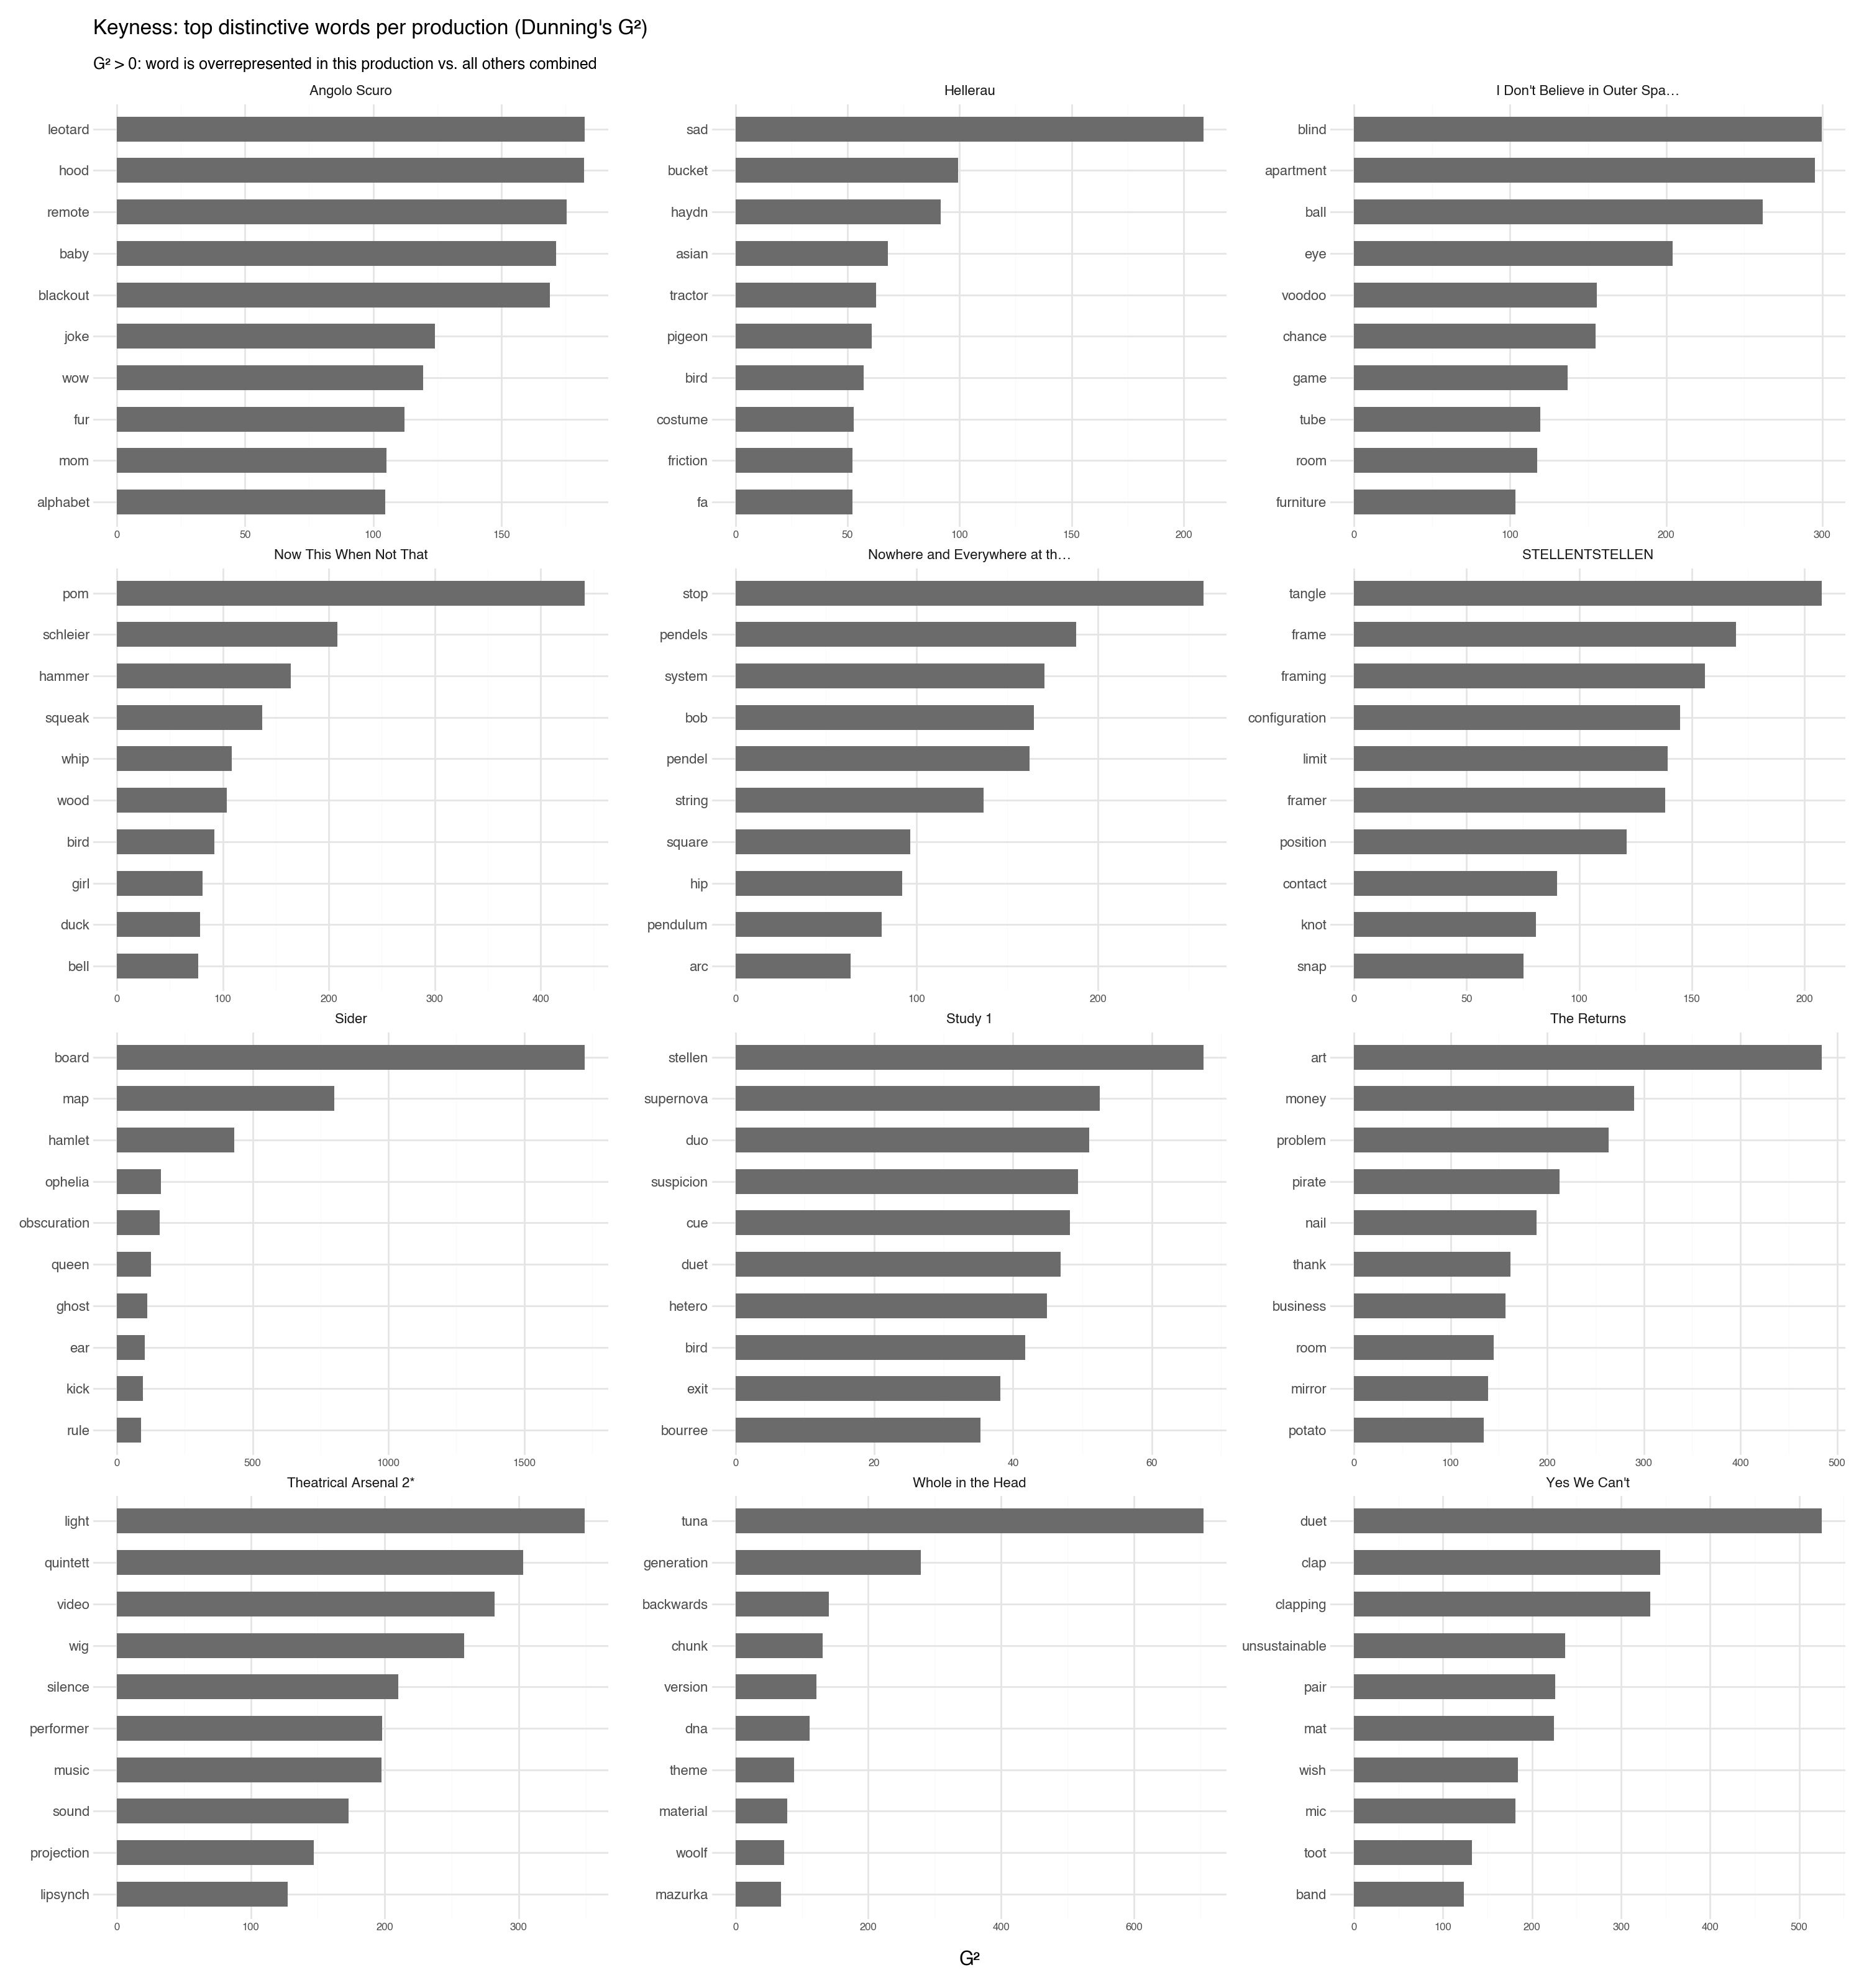

In [9]:
TOP_N = 10

top_per_piece = (
    base.sort_values(RANK_BY, ascending=False)
    .groupby('piece_id')
    .head(TOP_N)
    .copy()
)
top_per_piece['piece_short'] = top_per_piece['piece_id'].map(
    lambda p: shorten(piece_map.get(p, str(int(p)))))

# Per-facet ordering: unique key encodes piece + word
top_per_piece = top_per_piece.sort_values(['piece_short', RANK_BY], ascending=[True, True])
top_per_piece['word_key'] = top_per_piece['piece_short'] + '|' + top_per_piece['word']
top_per_piece['word_key'] = pd.Categorical(
    top_per_piece['word_key'], categories=top_per_piece['word_key'].tolist(), ordered=True)
label_map = {k: k.split('|')[1] for k in top_per_piece['word_key'].cat.categories}

p_facet = (
    ggplot(top_per_piece, aes(x='word_key', y=RANK_BY))
    + geom_col(fill=BAR_GREY, width=0.6)
    + coord_flip()
    + facet_wrap('~piece_short', scales='free', ncol=3)
    + scale_x_discrete(labels=label_map)
    + labs(title=L('Distinktive Wörter je Produktion (Dunnings G²)',
                   "Keyness: top distinctive words per production (Dunning's G²)"),
           subtitle=L('G² > 0: Wort ist in dieser Produktion gegenüber allen anderen überrepräsentiert',
                      'G² > 0: word is overrepresented in this production vs. all others combined'),
           x='', y='G²' if RANK_BY == 'g2' else 'Log Ratio')
    + theme(figure_size=(15, 16),
            axis_text_x=element_text(size=6),
            axis_text_y=element_text(size=8),
            strip_text=element_text(size=8, face='bold'))
)
p_facet

In [10]:
# Tabular summary: top 5 distinctive words per piece
summary = (
    base.sort_values(RANK_BY, ascending=False)
    .groupby('piece').head(5)
    .groupby('piece')['word']
    .apply(lambda ws: ', '.join(ws))
    .reset_index()
    .rename(columns={'piece': 'Piece', 'word': 'Top 5 distinctive words'})
    .sort_values('Piece')
    .reset_index(drop=True)
)
summary

,Piece,Top 5 distinctive words
0,Angolo Scuro,"leotard, hood, remote, baby, blackout"
1,Hellerau,"sad, bucket, haydn, asian, tractor"
2,I Don't Believe in Outer Space,"blind, apartment, ball, eye, voodoo"
3,Now This When Not That,"pom, schleier, hammer, squeak, whip"
4,Nowhere and Everywhere at the Same Time,"stop, pendels, system, bob, pendel"
5,STELLENTSTELLEN,"tangle, frame, framing, configuration, limit"
6,Sider,"board, map, hamlet, ophelia, obscuration"
7,Study 1,"stellen, supernova, duo, suspicion, cue"
8,The Returns,"art, money, problem, pirate, nail"
9,Theatrical Arsenal 2*,"light, quintett, video, wig, silence"


## A note on validity

Keyness compares vocabularies, not productions: it shows what was written down and how. The corpora are small (from a few hundred to about 17,000 tokens), and most annotations with an author come from one person, in very different shares per production. The results are entry points for viewing the recordings, not findings on their own.